# Lab 03 Demo: PyTorch and Transfer Learning Tools

**CCSFEN1L Software Engineering | #SL03 Transfer Learning for Image Classification**  

The tools behind today's lab: torchvision transforms and data augmentation, a pretrained ResNet-18, freezing layers and replacing the classifier head, and an `ImageFolder` dataset built from a small CIFAR-10 subset. The activity then compares transfer learning against training from scratch on your own image folders.

**Runtime:** Colab with a GPU (**Runtime > Change runtime type**); CPU works, more slowly  
**Time:** About 30 minutes

## 1. Device and versions

In [2]:
import torch, torchvision
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, models, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

ModuleNotFoundError: No module named 'torch'

## 2. Transforms and augmentation
Training images are randomly cropped and flipped so that the network sees a slightly different version every epoch. Validation images are resized and cropped the same way every time.

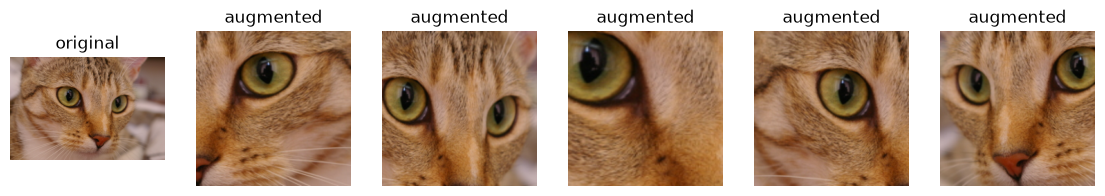

Normalization uses the ImageNet statistics the network was trained with: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]


In [ ]:
from PIL import Image
from skimage import data # pip install scikit-image

weights = models.ResNet18_Weights.DEFAULT
mean, std = weights.transforms().mean, weights.transforms().std
augment = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip()])

cat = Image.fromarray(data.chelsea())
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(cat); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(augment(cat)); ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.show()
print("Normalization uses the ImageNet statistics the network was trained with:", mean, std)

## 3. A pretrained network, used as is
ResNet-18 was trained on 1.2 million ImageNet photos in 1,000 categories. With no training on our side it already recognizes everyday objects.

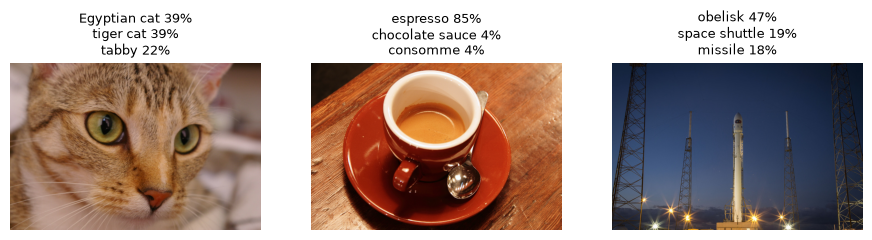

In [ ]:
net = models.resnet18(weights=weights).eval()
preprocess = weights.transforms()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, img in zip(axes, [data.chelsea(), data.coffee(), data.rocket()]):
    with torch.no_grad():
        probs = net(preprocess(Image.fromarray(img)).unsqueeze(0)).softmax(1)[0]
    top = probs.topk(3)
    ax.imshow(img); ax.axis("off")
    ax.set_title("\n".join(f"{weights.meta['categories'][i]} {p:.0%}"
                           for p, i in zip(top.values.tolist(), top.indices.tolist())), fontsize=9)
plt.show()

## 4. Anatomy, freezing, and a new head
For a new task we keep the early layers (general edges and textures), retrain the last block, and replace the final layer (`fc`) with one sized for our classes.

In [ ]:
def count(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return f"{trainable:,} trainable of {total:,}"

tl = models.resnet18(weights=weights)
print("Blocks:", [name for name, _ in tl.named_children()])
print("All layers trainable:     ", count(tl))

for name, p in tl.named_parameters():
    p.requires_grad = name.startswith("layer4") or name.startswith("fc")
tl.fc = nn.Linear(tl.fc.in_features, 3)          # new head for 3 classes
print("Only layer4 and new head: ", count(tl))

Blocks: ['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool', 'fc']
All layers trainable:      11,689,512 trainable of 11,689,512
Only layer4 and new head:  8,395,267 trainable of 11,178,051


## 5. An image-folder dataset
`ImageFolder` reads one subfolder per class, the same layout your team will use. Here we write 200 training and 60 validation images per class from CIFAR-10 (a 170 MB download the first time).

In [ ]:
import os
from torchvision.datasets import CIFAR10

def cifar_to_folders(root, classes, n_train, n_val):
    """Write a small CIFAR-10 subset as root/train/<class>/*.png and root/val/<class>/*.png."""
    cifar = CIFAR10("cifar", train=True, download=True)
    wanted = {cifar.class_to_idx[c]: c for c in classes}
    seen = {c: 0 for c in classes}
    for img, label in cifar:
        if label not in wanted:
            continue
        name = wanted[label]
        k = seen[name]
        if k >= n_train + n_val:
            continue
        split = "train" if k < n_train else "val"
        os.makedirs(f"{root}/{split}/{name}", exist_ok=True)
        img.save(f"{root}/{split}/{name}/{k}.png")
        seen[name] += 1
        if all(v >= n_train + n_val for v in seen.values()):
            break

cifar_to_folders("demo_data", ["cat", "dog", "ship"], n_train=200, n_val=60)

train_tf = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(mean, std)])
eval_tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), transforms.Normalize(mean, std)])
train_ds = datasets.ImageFolder("demo_data/train", transform=train_tf)
val_ds = datasets.ImageFolder("demo_data/val", transform=eval_tf)
print(train_ds.classes, len(train_ds), "training and", len(val_ds), "validation images")

['cat', 'dog', 'ship'] 600 training and 180 validation images


In [ ]:
from torch.utils.data import DataLoader

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=64, num_workers=2)
x, y = next(iter(train_dl))
print("One batch:", tuple(x.shape), "images and", tuple(y.shape), "labels")

One batch: (32, 3, 224, 224) images and (32,) labels


## 6. Two epochs of fine-tuning
One pass over the data with the optimizer is an *epoch*. The loss measures how wrong the network is; backpropagation computes how to change each trainable weight to reduce it. Even two epochs on 600 small images give a usable model, because most of the knowledge was already in the pretrained weights.

In [ ]:
import time

tl = tl.to(device)
opt = torch.optim.Adam([p for p in tl.parameters() if p.requires_grad], lr=1e-3)
for epoch in range(2):
    start, tl_loss = time.time(), 0.0
    tl.train()
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = nn.functional.cross_entropy(tl(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        tl_loss += loss.item() * len(y)
    tl.eval(); correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            correct += (tl(x.to(device)).argmax(1).cpu() == y).sum().item()
    print(f"epoch {epoch + 1}: train loss {tl_loss / len(train_ds):.3f} | "
          f"val accuracy {correct / len(val_ds):.3f} | {time.time() - start:.0f} s")

epoch 1: train loss 0.920 | val accuracy 0.644 | 30 s
epoch 2: train loss 0.574 | val accuracy 0.839 | 22 s


## Now you
In the activity your pair trains this setup **and** the same network from random weights, on the same data with the same settings, and compares them with curves, timings, and macro F1.

---
*CCSFEN1L Software Engineering laboratory notebooks | Shared under CC BY-NC-ND 4.0.*